In [8]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [9]:
!pip -q install h5py matplotlib opencv-python

In [14]:
!mkdir -p /content/drive/MyDrive/datasets/nyu
!wget -c -O /content/drive/MyDrive/datasets/nyu/nyu_depth_v2_labeled.mat \
  "https://horatio.cs.nyu.edu/mit/silberman/nyu_depth_v2/nyu_depth_v2_labeled.mat"

In [15]:
import h5py
import numpy as np

mat_path = "/content/drive/MyDrive/datasets/nyu/nyu_depth_v2_labeled.mat"
f = h5py.File(mat_path, "r")

print("keys:", list(f.keys()))
for k in ["images", "depths", "rawDepths", "labels"]:
    if k in f:
        print(k, f[k].shape, f[k].dtype)

keys: ['#refs#', '#subsystem#', 'accelData', 'depths', 'images', 'instances', 'labels', 'names', 'namesToIds', 'rawDepthFilenames', 'rawDepths', 'rawRgbFilenames', 'sceneTypes', 'scenes']
images (1449, 3, 640, 480) uint8
depths (1449, 640, 480) float32
rawDepths (1449, 640, 480) float32
labels (1449, 640, 480) uint16


img: (480, 640, 3) uint8
depth: (480, 640) float32 min/max: 1.7985953 3.615639
label: (480, 640) uint16


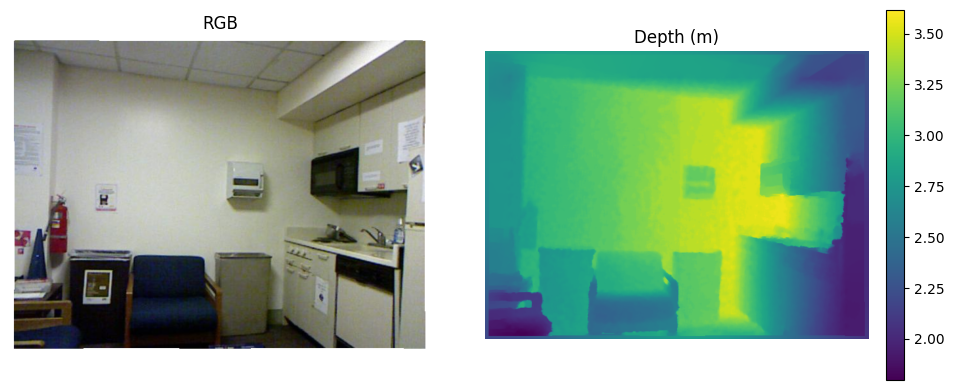

In [17]:
import matplotlib.pyplot as plt

def get_nyu_image(f, idx):
    d = f["images"]
    # نمونه را از محور اول یا آخر برمی‌داریم (بسته به شکل دیتاست)
    arr = np.array(d[idx] if d.shape[0] < 10000 else d[..., idx])

    # اگر محور کانال (3) اول باشد، منتقلش کن آخر
    if arr.ndim == 3 and arr.shape[0] == 3:
        arr = np.transpose(arr, (2, 1, 0))  # common NYU h5py case
    elif arr.ndim == 3 and arr.shape[-1] == 3:
        pass
    else:
        # حالت‌های دیگر: کانال را پیدا کن و ببَر آخر
        if arr.ndim == 3 and 3 in arr.shape:
            ch = list(arr.shape).index(3)
            arr = np.moveaxis(arr, ch, -1)

    # اگر H/W جابه‌جا بود
    if arr.ndim == 3 and arr.shape[0] == 640 and arr.shape[1] == 480:
        arr = np.transpose(arr, (1, 0, 2))

    return arr.astype(np.uint8)

def get_nyu_map(f, key, idx):
    d = f[key]
    arr = np.array(d[idx] if d.shape[0] < 10000 else d[..., idx])

    if arr.ndim == 2 and arr.shape == (640, 480):
        arr = arr.T
    return arr

idx = 0
img   = get_nyu_image(f, idx)
depth = get_nyu_map(f, "depths", idx)      # in-painted depth (meters)
label = get_nyu_map(f, "labels", idx)

print("img:", img.shape, img.dtype)
print("depth:", depth.shape, depth.dtype, "min/max:", np.nanmin(depth), np.nanmax(depth))
print("label:", label.shape, label.dtype)

plt.figure(figsize=(14,4))

plt.subplot(1,3,1)
plt.imshow(img)
plt.title("RGB")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(depth, cmap="viridis")
plt.title("Depth (m)")
plt.axis("off")
plt.colorbar(fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

# load object detection and depth estimation model

In [19]:
!rm -rf /content/yolov13


In [23]:
%cd /content
!pwd
!ls -la
!git clone https://github.com/iMoonLab/yolov13.git
%cd /content/yolov13

/content
/content
total 20
drwxr-xr-x 1 root root 4096 Feb 22 14:24 .
drwxr-xr-x 1 root root 4096 Feb 22 12:56 ..
drwxr-xr-x 4 root root 4096 Jan 16 14:24 .config
drwx------ 5 root root 4096 Feb 22 13:00 drive
drwxr-xr-x 1 root root 4096 Jan 16 14:24 sample_data
Cloning into 'yolov13'...
remote: Enumerating objects: 527, done.
remote: Counting objects: 100% (298/298), done.
remote: Compressing objects: 100% (182/182), done.
remote: Total 527 (delta 135), reused 116 (delta 116), pack-reused 229 (from 2)
Receiving objects: 100% (527/527), 29.91 MiB | 20.07 MiB/s, done.
Resolving deltas: 100% (159/159), done.
/content/yolov13


In [26]:
%cd /content/yolov13

# (اگر قبلاً نزدی، dependencies را نصب کن)
!pip install -r requirements.txt
!pip install -e .

# وزن مدل (نسخه سبک)
!wget -nc https://github.com/iMoonLab/yolov13/releases/download/yolov13/yolov13s.pt

/content/yolov13
ERROR: flash_attn-2.7.3+cu11torch2.2cxx11abiFALSE-cp311-cp311-linux_x86_64.whl is not a supported wheel on this platform.
Obtaining file:///content/yolov13
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Created wheel for ultralytics: filename=ultralytics-8.3.63-0.editable-py3-none-any.whl size=20483 sha256=c0dd750c2cd1f1725949d3f55cfb316ca243a5acedb386ad67f23d664c018535
  Stored in directory: /tmp/pip-ephem-wheel-cache-gzh3wa1i/wheels/52/98/bf/402e0bccd80ed093c2cf8857ceab45db5da5935b4ad0fb44c2
Successfully built ultralytics
  Attempting uninstall: ultralytics
    Found existing installation: ultralytics 8.3.63
    Uninstalling ultralytics-8.3.63:
      Successfully uninstalled ultralytics-8.3.63
--2026-02-22 14:38:40--  https://github.com/iMoonLab/

In [35]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

mat_path = "/content/drive/MyDrive/datasets/nyu/nyu_depth_v2_labeled.mat"
assert os.path.exists(mat_path), f"File not found: {mat_path}"

# مدل YOLOv13
model = YOLO("/content/yolov13/yolov13s.pt")

def to_hwc_uint8(arr):
    arr = np.asarray(arr)

    if arr.ndim != 3:
        raise ValueError(f"Expected 3D image array, got shape={arr.shape}")

    # پیدا کردن محور کانال
    axes_with_3 = [i for i, s in enumerate(arr.shape) if s == 3]
    if not axes_with_3:
        raise ValueError(f"Could not find channel axis=3 in shape={arr.shape}")

    c_axis = axes_with_3[0]
    if c_axis != 2:
        arr = np.moveaxis(arr, c_axis, -1)  # -> HxWx3 (تقریبی)

    # uint8
    if arr.dtype != np.uint8:
        arr = np.clip(arr, 0, 255).astype(np.uint8)

    # NYU باید معمولاً 480x640 باشد.
    # اگر 640x480 شد یعنی H/W جابه‌جا شده‌اند.
    if arr.shape[:2] == (640, 480):
        arr = np.transpose(arr, (1, 0, 2))  # -> 480x640x3

    return np.ascontiguousarray(arr)

def run_random_nyu_detection(mat_path, model, conf=0.25, imgsz=640, seed=None):
    if seed is not None:
        random.seed(seed)
        np.random.seed(seed)

    # اول scipy را امتحان می‌کنیم
    try:
        from scipy.io import loadmat
        data = loadmat(mat_path)
        if "images" not in data:
            raise KeyError("'images' key not found in mat file")

        images = data["images"]
        print("Loaded with scipy | images.shape =", images.shape, "| dtype =", images.dtype)

        # پیدا کردن محور تعداد فریم‌ها (معمولاً بزرگ‌ترین بعد مثل 1449)
        n_axis = int(np.argmax(images.shape))
        n_frames = images.shape[n_axis]
        idx = random.randint(0, n_frames - 1)

        # برش رندوم روی همان محور
        frame = np.take(images, indices=idx, axis=n_axis)
        rgb = to_hwc_uint8(frame)

    except Exception as e_scipy:
        print("scipy loadmat failed or incompatible, trying h5py...")
        print("scipy error:", e_scipy)

        import h5py
        with h5py.File(mat_path, "r") as f:
            if "images" not in f:
                raise KeyError("'images' key not found in HDF5 mat file")
            images = f["images"]
            print("Loaded with h5py | images.shape =", images.shape, "| dtype =", images.dtype)

            n_axis = int(np.argmax(images.shape))   # معمولاً بعد تعداد نمونه‌ها
            n_frames = images.shape[n_axis]
            idx = random.randint(0, n_frames - 1)

            frame = np.take(images, indices=idx, axis=n_axis)
            rgb = to_hwc_uint8(frame)

    # YOLO معمولاً ndarray را هم قبول می‌کند
    # بهتره RGB را به BGR تبدیل کنیم چون plot/cv2 با BGR راحت‌تر است (اختیاری)
    bgr = cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR)

    result = model.predict(source=bgr, conf=conf, imgsz=imgsz, verbose=False)[0]
    vis = result.plot()  # خروجی تصویری با باکس‌ها (BGR)

    print(f"Random frame index: {idx}")
    print("Detections:", len(result.boxes) if result.boxes is not None else 0)

    # نمایش
    plt.figure(figsize=(10, 6))
    plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
    plt.axis("off")
    plt.show()

    return result, idx, rgb

In [36]:
import numpy as np
import h5py
from scipy.io import loadmat

def _extract_sample_by_idx(arr, idx):
    """نمونه idx را از آرایه‌ای که محور sample آن مشخص نیست استخراج می‌کند."""
    arr_shape = arr.shape
    n_axis = int(np.argmax(arr_shape))   # معمولاً محور تعداد فریم‌ها بزرگ‌ترین است
    sample = np.take(arr, indices=idx, axis=n_axis)
    return np.array(sample)

def _to_hw_float_depth(depth_arr):
    depth = np.asarray(depth_arr).squeeze()
    if depth.ndim != 2:
        raise ValueError(f"Depth map must be 2D after squeeze, got shape={depth.shape}")
    return depth.astype(np.float32)

def _align_depth_to_rgb_shape(depth, rgb_shape):
    """depth را طوری می‌چرخاند/transpose می‌کند که shape آن با rgb یکی شود."""
    H, W = rgb_shape[:2]
    candidates = [
        depth,
        depth.T,
        np.rot90(depth, 1),
        np.rot90(depth, 2),
        np.rot90(depth, 3),
        np.rot90(depth.T, 1),
        np.rot90(depth.T, 2),
        np.rot90(depth.T, 3),
    ]
    for c in candidates:
        if c.shape == (H, W):
            return np.ascontiguousarray(c)
    raise ValueError(f"Could not align depth shape {depth.shape} to RGB shape {(H, W)}")

def get_nyu_depth_by_idx(mat_path, idx, rgb_shape=None):
    """
    depth فریم idx را از nyu_depth_v2_labeled.mat می‌خواند.
    اگر rgb_shape بدهی، depth را با همان shape align می‌کند.
    """
    depth = None

    # اول scipy
    try:
        data = loadmat(mat_path)
        if "depths" in data:
            depths = data["depths"]
            depth = _extract_sample_by_idx(depths, idx)
    except Exception:
        depth = None

    # اگر scipy جواب نداد -> h5py
    if depth is None:
        with h5py.File(mat_path, "r") as f:
            if "depths" not in f:
                raise KeyError("'depths' key not found in mat file")
            depths = f["depths"]
            depth = _extract_sample_by_idx(depths, idx)

    depth = _to_hw_float_depth(depth)

    if rgb_shape is not None:
        depth = _align_depth_to_rgb_shape(depth, rgb_shape)

    return depth

In [40]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

def show_rgb_detection_depth_and_histograms(result, rgb, depth_map, bins=40, ignore_zero=True, max_objects=None):
    """
    result   : خروجی model.predict(...)[0]
    rgb      : تصویر RGB هم‌راستا با result (HxWx3)
    depth_map: depth map هم‌راستا با rgb (HxW)
    """
    if rgb is None or depth_map is None:
        raise ValueError("rgb و depth_map نباید None باشند")

    H, W = rgb.shape[:2]
    if depth_map.shape != (H, W):
        raise ValueError(f"depth_map shape {depth_map.shape} با rgb shape {(H, W)} هم‌راستا نیست")

    # تصویر detection شده (result.plot خروجی BGR می‌دهد)
    det_bgr = result.plot()
    det_rgb = cv2.cvtColor(det_bgr, cv2.COLOR_BGR2RGB)

    # depth map برای نمایش (normalize فقط برای visualization)
    d = depth_map.astype(np.float32).copy()
    valid_vis = np.isfinite(d)
    if ignore_zero:
        valid_vis &= (d > 0)

    depth_vis = np.zeros_like(d, dtype=np.float32)
    if valid_vis.any():
        lo, hi = np.percentile(d[valid_vis], [1, 99])
        depth_vis = np.clip((d - lo) / (hi - lo + 1e-6), 0, 1)

    # اطلاعات detections
    if result.boxes is None or len(result.boxes) == 0:
        print("هیچ آبجکتی تشخیص داده نشد.")

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))
        axes[0].imshow(rgb)
        axes[0].set_title("RGB (Original)")
        axes[0].axis("off")

        axes[1].imshow(det_rgb)
        axes[1].set_title("Detections (none)")
        axes[1].axis("off")

        axes[2].imshow(depth_vis, cmap="viridis")
        axes[2].set_title("Depth Map")
        axes[2].axis("off")
        plt.tight_layout()
        plt.show()
        return []

    boxes_xyxy = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy() if result.boxes.conf is not None else np.array([np.nan] * len(boxes_xyxy))
    clss  = result.boxes.cls.cpu().numpy().astype(int) if result.boxes.cls is not None else np.array([-1] * len(boxes_xyxy))

    # محدودسازی تعداد آبجکت‌ها (اختیاری)
    n_total = len(boxes_xyxy)
    n_show = n_total if max_objects is None else min(max_objects, n_total)

    # --- نمایش کلی: RGB + Detections + Depth with boxes ---
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))

    # 1) تصویر اصلی
    axes[0].imshow(rgb)
    axes[0].set_title(f"RGB (Original) | idx frame")
    axes[0].axis("off")

    # 2) تصویر با detections
    axes[1].imshow(det_rgb)
    axes[1].set_title(f"YOLO Detections ({n_total})")
    axes[1].axis("off")

    # 3) depth map + bbox ها
    axes[2].imshow(depth_vis, cmap="viridis")
    axes[2].set_title("Depth Map + BBoxes")
    axes[2].axis("off")

    summaries = []

    for i in range(n_show):
        x1, y1, x2, y2 = boxes_xyxy[i]
        conf = float(confs[i]) if np.isfinite(confs[i]) else None
        cls_id = int(clss[i])
        class_name = result.names.get(cls_id, str(cls_id)) if hasattr(result, "names") else str(cls_id)

        # clip + int
        x1 = max(0, min(W - 1, int(np.floor(x1))))
        y1 = max(0, min(H - 1, int(np.floor(y1))))
        x2 = max(0, min(W,     int(np.ceil(x2))))
        y2 = max(0, min(H,     int(np.ceil(y2))))

        if x2 <= x1 or y2 <= y1:
            continue

        # رسم bbox روی RGB اصلی
        rect_rgb = Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2)
        axes[0].add_patch(rect_rgb)
        axes[0].text(x1, max(0, y1 - 5), f"{i}:{class_name} {conf:.2f}" if conf is not None else f"{i}:{class_name}",
                     fontsize=9, backgroundcolor="black", color="white")

        # رسم bbox روی depth
        rect_d = Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, linewidth=2)
        axes[2].add_patch(rect_d)
        axes[2].text(x1, max(0, y1 - 5), f"{i}:{class_name}", fontsize=9, backgroundcolor="black", color="white")

    plt.tight_layout()
    plt.show()

    # --- نمایش جزئیات هر detection: crop RGB + crop depth + histogram ---
    for i in range(n_show):
        x1, y1, x2, y2 = boxes_xyxy[i]
        conf = float(confs[i]) if np.isfinite(confs[i]) else None
        cls_id = int(clss[i])
        class_name = result.names.get(cls_id, str(cls_id)) if hasattr(result, "names") else str(cls_id)

        x1 = max(0, min(W - 1, int(np.floor(x1))))
        y1 = max(0, min(H - 1, int(np.floor(y1))))
        x2 = max(0, min(W,     int(np.ceil(x2))))
        y2 = max(0, min(H,     int(np.ceil(y2))))

        if x2 <= x1 or y2 <= y1:
            continue

        rgb_crop = rgb[y1:y2, x1:x2]
        depth_crop = depth_map[y1:y2, x1:x2]

        total_pixels = int(depth_crop.size)
        valid_mask = np.isfinite(depth_crop)
        if ignore_zero:
            valid_mask &= (depth_crop > 0)
        valid_depth = depth_crop[valid_mask]
        valid_pixels = int(valid_mask.sum())

        print(f"[{i}] class={class_name} | conf={conf:.2f}" if conf is not None else f"[{i}] class={class_name}")
        print(f"    bbox=(x1={x1}, y1={y1}, x2={x2}, y2={y2})")
        print(f"    total pixels in bbox = {total_pixels}")
        print(f"    valid depth pixels   = {valid_pixels}")

        fig, ax = plt.subplots(1, 3, figsize=(18, 4))

        # crop RGB
        ax[0].imshow(rgb_crop)
        ax[0].set_title(f"RGB Crop | {class_name}")
        ax[0].axis("off")

        # crop depth (visual)
        if valid_mask.any():
            d_local = depth_crop.astype(np.float32).copy()
            local_valid = np.isfinite(d_local)
            if ignore_zero:
                local_valid &= (d_local > 0)
            lo, hi = np.percentile(d_local[local_valid], [1, 99]) if local_valid.any() else (0, 1)
            d_local = np.clip((d_local - lo) / (hi - lo + 1e-6), 0, 1)
            ax[1].imshow(d_local, cmap="viridis")
        else:
            ax[1].imshow(np.zeros_like(depth_crop), cmap="viridis")
        ax[1].set_title(f"Depth Crop | valid={valid_pixels}")
        ax[1].axis("off")

        # histogram
        if valid_depth.size > 0:
            ax[2].hist(valid_depth.ravel(), bins=bins)
            ax[2].set_xlabel("Depth value")
            ax[2].set_ylabel("Pixel count")
            ax[2].set_title("Depth Histogram")
        else:
            ax[2].text(0.5, 0.5, "No valid depth pixels", ha="center", va="center")
            ax[2].set_title("Depth Histogram")
            ax[2].axis("off")

        plt.tight_layout()
        plt.show()

        summaries.append({
            "det_id": i,
            "class_name": class_name,
            "conf": conf,
            "bbox": (x1, y1, x2, y2),
            "bbox_total_pixels": total_pixels,
            "valid_depth_pixels": valid_pixels,
            "depth_min": float(valid_depth.min()) if valid_depth.size else None,
            "depth_max": float(valid_depth.max()) if valid_depth.size else None,
            "depth_mean": float(valid_depth.mean()) if valid_depth.size else None,
            "depth_median": float(np.median(valid_depth)) if valid_depth.size else None,
        })

    return summaries

In [42]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def show_detection_and_object_depth_histograms(result, rgb, depth_map, bins=40, ignore_zero=True):
    """
    result: خروجی model.predict(...)[0]
    rgb: تصویر RGB همان فریم (HxWx3)
    depth_map: depth map هم‌راستا با rgb (HxW)
    """
    H, W = rgb.shape[:2]
    assert depth_map.shape == (H, W), f"depth_map shape={depth_map.shape} must match rgb shape={(H, W)}"

    # 1) نمایش تصویر detection شده
    det_rgb = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)
    plt.figure(figsize=(8, 6))
    plt.imshow(det_rgb)
    plt.axis("off")
    plt.title("Object Detection نتیجه")
    plt.show()

    # اگر آبجکتی نبود
    if result.boxes is None or len(result.boxes) == 0:
        print("هیچ آبجکتی تشخیص داده نشد.")
        return []

    boxes_xyxy = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy() if result.boxes.conf is not None else np.array([np.nan] * len(boxes_xyxy))
    clss  = result.boxes.cls.cpu().numpy().astype(int) if result.boxes.cls is not None else np.array([-1] * len(boxes_xyxy))

    summaries = []

    # 2) برای هر object: crop + histogram depth
    for i, (xyxy, conf, cls_id) in enumerate(zip(boxes_xyxy, confs, clss)):
        x1, y1, x2, y2 = xyxy

        # clip و تبدیل به int
        x1 = max(0, min(W - 1, int(np.floor(x1))))
        y1 = max(0, min(H - 1, int(np.floor(y1))))
        x2 = max(0, min(W,     int(np.ceil(x2))))
        y2 = max(0, min(H,     int(np.ceil(y2))))

        if x2 <= x1 or y2 <= y1:
            continue

        rgb_crop = rgb[y1:y2, x1:x2]
        depth_crop = depth_map[y1:y2, x1:x2]

        total_pixels = int(depth_crop.size)

        valid_mask = np.isfinite(depth_crop)
        if ignore_zero:
            valid_mask &= (depth_crop > 0)

        valid_depth = depth_crop[valid_mask]
        valid_pixels = int(valid_mask.sum())

        class_name = result.names.get(int(cls_id), str(cls_id)) if hasattr(result, "names") else str(cls_id)

        print(f"[{i}] {class_name} | conf={float(conf):.2f}")
        print(f"    bbox=({x1},{y1},{x2},{y2})")
        print(f"    pixels in bbox: {total_pixels}")
        print(f"    valid depth pixels: {valid_pixels}")

        # نمایش crop + histogram
        fig, ax = plt.subplots(1, 2, figsize=(12, 4))

        ax[0].imshow(rgb_crop)
        ax[0].axis("off")
        ax[0].set_title(f"Object #{i}: {class_name}")

        if valid_depth.size > 0:
            ax[1].hist(valid_depth.ravel(), bins=bins)
            ax[1].set_xlabel("Depth value")
            ax[1].set_ylabel("Pixel count")
            ax[1].set_title(f"Depth Histogram | valid={valid_pixels}")
        else:
            ax[1].text(0.5, 0.5, "No valid depth pixels", ha="center", va="center")
            ax[1].set_title("Depth Histogram")
            ax[1].axis("off")

        plt.tight_layout()
        plt.show()

        summaries.append({
            "det_id": i,
            "class_name": class_name,
            "conf": float(conf),
            "bbox": (x1, y1, x2, y2),
            "bbox_total_pixels": total_pixels,
            "valid_depth_pixels": valid_pixels,
            "depth_min": float(valid_depth.min()) if valid_depth.size else None,
            "depth_max": float(valid_depth.max()) if valid_depth.size else None,
            "depth_mean": float(valid_depth.mean()) if valid_depth.size else None,
        })

    return summaries

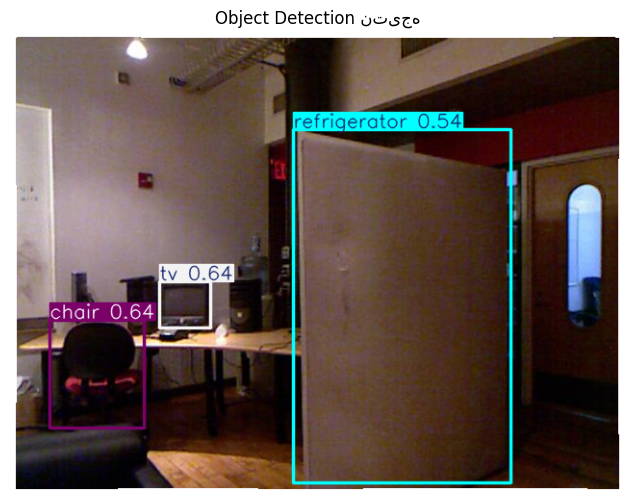

[0] chair | conf=0.64
    bbox=(41,299,140,412)
    pixels in bbox: 11187
    valid depth pixels: 11187


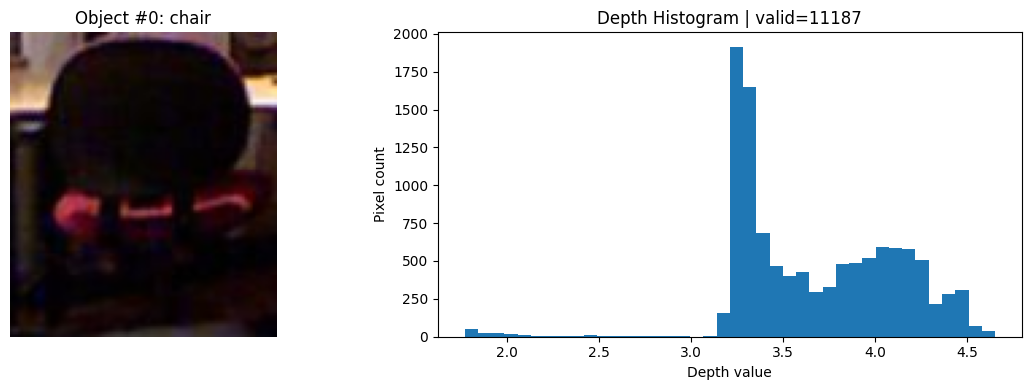

[1] tv | conf=0.64
    bbox=(155,259,209,308)
    pixels in bbox: 2646
    valid depth pixels: 2646


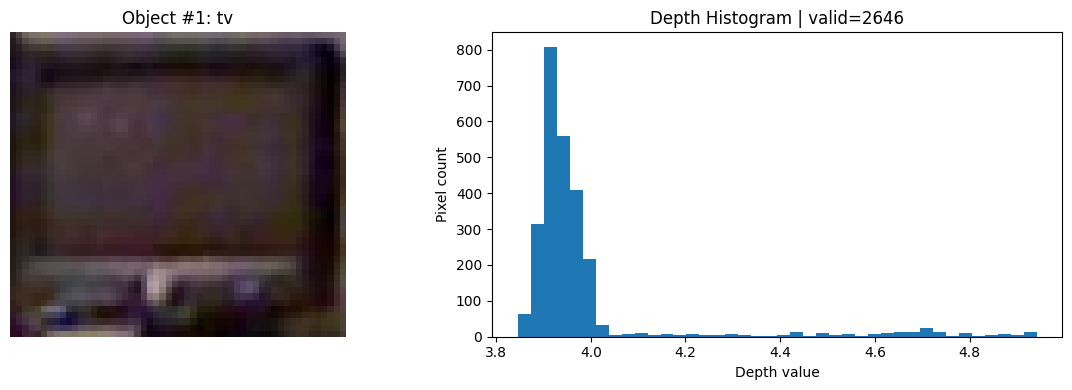

[2] refrigerator | conf=0.54
    bbox=(294,101,521,469)
    pixels in bbox: 83536
    valid depth pixels: 83536


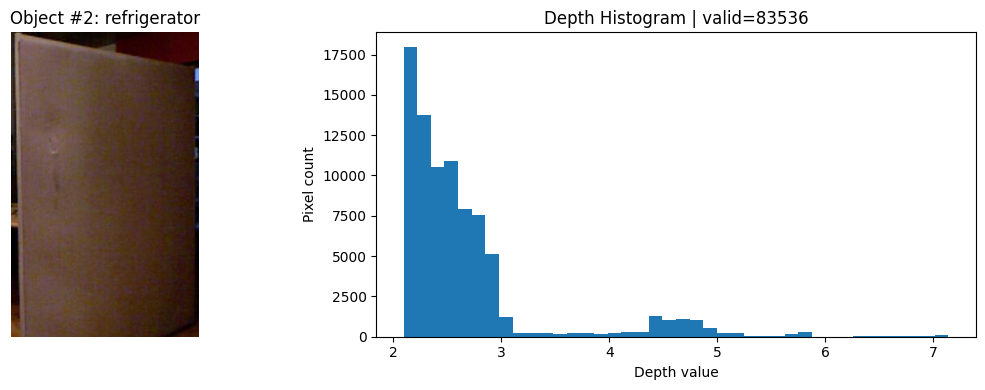

[{'det_id': 0,
  'class_name': 'chair',
  'conf': 0.6385251879692078,
  'bbox': (41, 299, 140, 412),
  'bbox_total_pixels': 11187,
  'valid_depth_pixels': 11187,
  'depth_min': 1.7709921598434448,
  'depth_max': 4.652000427246094,
  'depth_mean': 3.6690917015075684},
 {'det_id': 1,
  'class_name': 'tv',
  'conf': 0.6374461650848389,
  'bbox': (155, 259, 209, 308),
  'bbox_total_pixels': 2646,
  'valid_depth_pixels': 2646,
  'depth_min': 3.8460981845855713,
  'depth_max': 4.941328525543213,
  'depth_mean': 3.9895870685577393},
 {'det_id': 2,
  'class_name': 'refrigerator',
  'conf': 0.5395836234092712,
  'bbox': (294, 101, 521, 469),
  'bbox_total_pixels': 83536,
  'valid_depth_pixels': 83536,
  'depth_min': 2.097334861755371,
  'depth_max': 7.137178897857666,
  'depth_mean': 2.6719248294830322}]

In [43]:
depth_map = get_nyu_depth_by_idx(mat_path, idx, rgb_shape=rgb.shape)

summaries = show_detection_and_object_depth_histograms(
    result=result,
    rgb=rgb,
    depth_map=depth_map,
    bins=40,
    ignore_zero=True
)

summaries

In [44]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

def clean_depth_values(depth_values, method="mad", mad_thresh=3.5, iqr_k=1.5, p_low=5, p_high=95):
    """
    depth_values: آرایه 1بعدی depth معتبر (float, meter)
    خروجی: cleaned_values, info
    """
    x = np.asarray(depth_values, dtype=np.float32)
    x = x[np.isfinite(x)]
    x = x[x > 0]

    if x.size == 0:
        return x, {"method": method, "removed": 0, "kept": 0}

    if method == "percentile":
        lo = np.percentile(x, p_low)
        hi = np.percentile(x, p_high)
        m = (x >= lo) & (x <= hi)

    elif method == "iqr":
        q1, q3 = np.percentile(x, [25, 75])
        iqr = q3 - q1
        lo = q1 - iqr_k * iqr
        hi = q3 + iqr_k * iqr
        m = (x >= lo) & (x <= hi)

    elif method == "mad":
        med = np.median(x)
        mad = np.median(np.abs(x - med))

        # اگر mad خیلی کوچک بود، fallback به percentile
        if mad < 1e-8:
            lo = np.percentile(x, 5)
            hi = np.percentile(x, 95)
            m = (x >= lo) & (x <= hi)
        else:
            modified_z = 0.6745 * (x - med) / mad
            m = np.abs(modified_z) <= mad_thresh

    else:
        raise ValueError("method must be one of: 'mad', 'iqr', 'percentile'")

    cleaned = x[m]
    return cleaned, {
        "method": method,
        "removed": int((~m).sum()),
        "kept": int(m.sum()),
        "total_valid_before_clean": int(x.size),
    }


def estimate_object_distances_from_depth(
    result,
    rgb,
    depth_map,
    bins=40,
    ignore_zero=True,
    outlier_method="mad",   # "mad" | "iqr" | "percentile"
    show_plots=True
):
    """
    result: خروجی YOLO -> model.predict(...)[0]
    rgb: تصویر RGB همان فریم (HxWx3)
    depth_map: depth هم‌راستا با rgb (HxW), واحد = متر (NYU depths)
    """
    H, W = rgb.shape[:2]
    assert depth_map.shape == (H, W), f"depth_map shape={depth_map.shape} != {(H, W)}"

    # تصویر detection شده
    det_rgb = cv2.cvtColor(result.plot(), cv2.COLOR_BGR2RGB)

    if show_plots:
        plt.figure(figsize=(8, 6))
        plt.imshow(det_rgb)
        plt.title("Object Detection")
        plt.axis("off")
        plt.show()

    if result.boxes is None or len(result.boxes) == 0:
        print("هیچ آبجکتی تشخیص داده نشد.")
        return []

    boxes_xyxy = result.boxes.xyxy.cpu().numpy()
    confs = result.boxes.conf.cpu().numpy() if result.boxes.conf is not None else np.array([np.nan] * len(boxes_xyxy))
    clss  = result.boxes.cls.cpu().numpy().astype(int) if result.boxes.cls is not None else np.array([-1] * len(boxes_xyxy))

    outputs = []

    for i, (xyxy, conf, cls_id) in enumerate(zip(boxes_xyxy, confs, clss)):
        x1, y1, x2, y2 = xyxy

        # bbox -> int + clip
        x1 = max(0, min(W - 1, int(np.floor(x1))))
        y1 = max(0, min(H - 1, int(np.floor(y1))))
        x2 = max(0, min(W,     int(np.ceil(x2))))
        y2 = max(0, min(H,     int(np.ceil(y2))))

        if x2 <= x1 or y2 <= y1:
            continue

        rgb_crop = rgb[y1:y2, x1:x2]
        depth_crop = depth_map[y1:y2, x1:x2]

        # valid depth mask
        valid_mask = np.isfinite(depth_crop)
        if ignore_zero:
            valid_mask &= (depth_crop > 0)

        depth_valid = depth_crop[valid_mask].astype(np.float32)
        total_pixels = int(depth_crop.size)
        valid_pixels = int(depth_valid.size)

        class_name = result.names.get(int(cls_id), str(cls_id)) if hasattr(result, "names") else str(cls_id)

        # حذف outlier
        depth_clean, clean_info = clean_depth_values(depth_valid, method=outlier_method)

        # آمار نهایی (به متر)
        if depth_clean.size > 0:
            mean_m = float(np.mean(depth_clean))
            median_m = float(np.median(depth_clean))
            min_m = float(np.min(depth_clean))
            max_m = float(np.max(depth_clean))
        else:
            mean_m = median_m = min_m = max_m = None

        print(f"\n[{i}] {class_name} | conf={float(conf):.2f}")
        print(f"    bbox=({x1},{y1},{x2},{y2})")
        print(f"    bbox pixels          : {total_pixels}")
        print(f"    valid depth pixels   : {valid_pixels}")
        print(f"    after outlier remove : {clean_info['kept']} (removed {clean_info['removed']})")
        if mean_m is not None:
            print(f"    distance mean   (m)  : {mean_m:.3f}")
            print(f"    distance median (m)  : {median_m:.3f}")
            print(f"    min/max         (m)  : {min_m:.3f} / {max_m:.3f}")
        else:
            print("    depth clean is empty.")

        if show_plots:
            fig, ax = plt.subplots(1, 3, figsize=(16, 4))

            # crop RGB
            ax[0].imshow(rgb_crop)
            ax[0].axis("off")
            ax[0].set_title(f"Object #{i}: {class_name}")

            # histogram قبل/بعد
            if depth_valid.size > 0:
                ax[1].hist(depth_valid, bins=bins)
                ax[1].set_title(f"Depth Hist (Before)\nvalid={depth_valid.size}")
                ax[1].set_xlabel("Depth (meter)")
                ax[1].set_ylabel("Pixel count")
            else:
                ax[1].text(0.5, 0.5, "No valid depth", ha="center", va="center")
                ax[1].axis("off")
                ax[1].set_title("Depth Hist (Before)")

            if depth_clean.size > 0:
                ax[2].hist(depth_clean, bins=bins)
                ax[2].axvline(mean_m, linestyle="--", label=f"mean={mean_m:.2f}m")
                ax[2].axvline(median_m, linestyle=":", label=f"median={median_m:.2f}m")
                ax[2].legend()
                ax[2].set_title(f"Depth Hist (After {outlier_method})\nkept={depth_clean.size}")
                ax[2].set_xlabel("Depth (meter)")
                ax[2].set_ylabel("Pixel count")
            else:
                ax[2].text(0.5, 0.5, "No depth after cleaning", ha="center", va="center")
                ax[2].axis("off")
                ax[2].set_title("Depth Hist (After)")

            plt.tight_layout()
            plt.show()

        outputs.append({
            "det_id": i,
            "class_name": class_name,
            "conf": float(conf),
            "bbox": (x1, y1, x2, y2),
            "bbox_total_pixels": total_pixels,
            "valid_depth_pixels": valid_pixels,
            "clean_depth_pixels": int(depth_clean.size),
            "mean_distance_m": mean_m,
            "median_distance_m": median_m,
            "min_distance_m": min_m,
            "max_distance_m": max_m,
            "outlier_method": outlier_method,
            "clean_info": clean_info,
        })

    return outputs

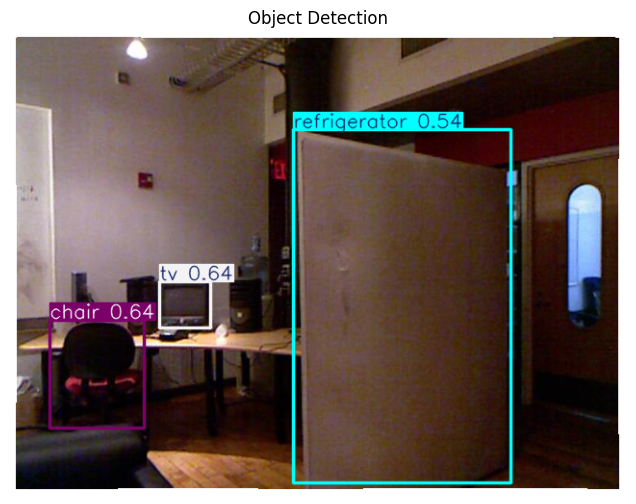


[0] chair | conf=0.64
    bbox=(41,299,140,412)
    bbox pixels          : 11187
    valid depth pixels   : 11187
    after outlier remove : 11118 (removed 69)
    distance mean   (m)  : 3.681
    distance median (m)  : 3.605
    min/max         (m)  : 1.893 / 4.652


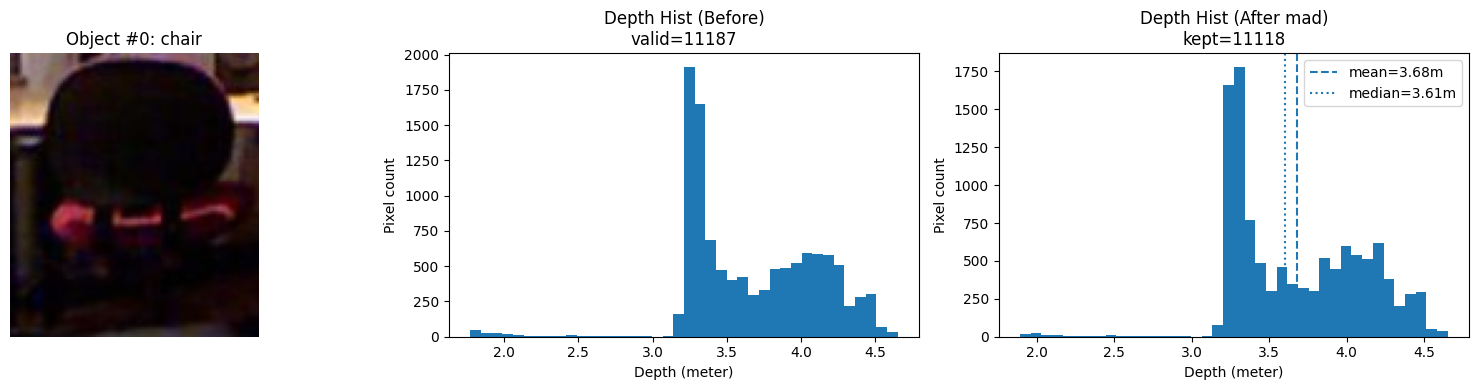


[1] tv | conf=0.64
    bbox=(155,259,209,308)
    bbox pixels          : 2646
    valid depth pixels   : 2646
    after outlier remove : 2410 (removed 236)
    distance mean   (m)  : 3.935
    distance median (m)  : 3.929
    min/max         (m)  : 3.846 / 4.055


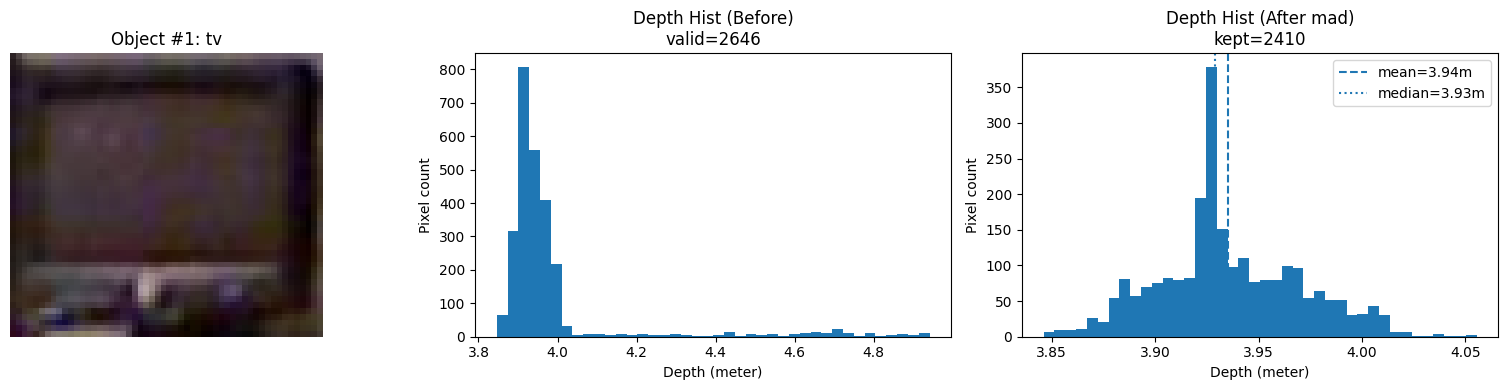


[2] refrigerator | conf=0.54
    bbox=(294,101,521,469)
    bbox pixels          : 83536
    valid depth pixels   : 83536
    after outlier remove : 75968 (removed 7568)
    distance mean   (m)  : 2.467
    distance median (m)  : 2.424
    min/max         (m)  : 2.097 / 3.704


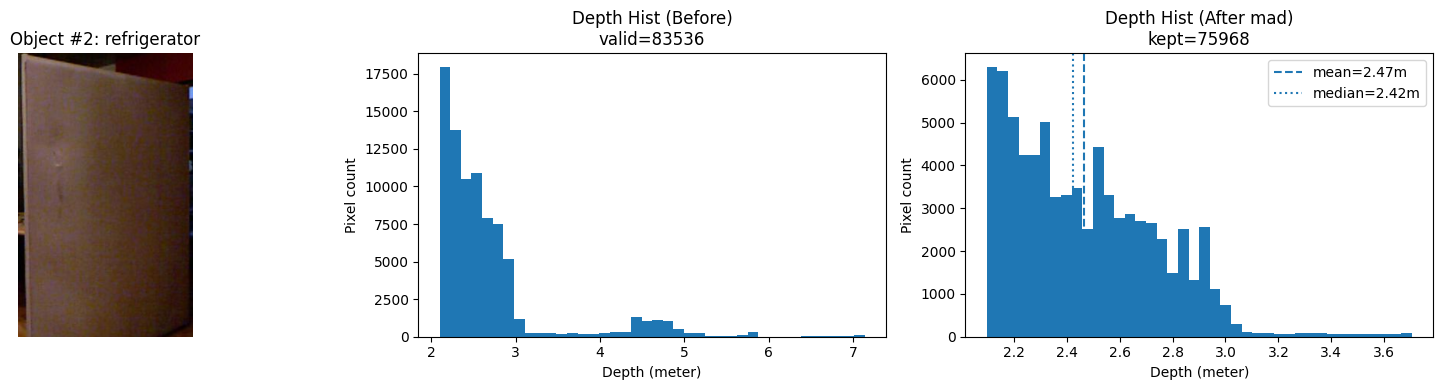

[{'det_id': 0,
  'class_name': 'chair',
  'conf': 0.6385251879692078,
  'bbox': (41, 299, 140, 412),
  'bbox_total_pixels': 11187,
  'valid_depth_pixels': 11187,
  'clean_depth_pixels': 11118,
  'mean_distance_m': 3.6805620193481445,
  'median_distance_m': 3.6050057411193848,
  'min_distance_m': 1.8927241563796997,
  'max_distance_m': 4.652000427246094,
  'outlier_method': 'mad',
  'clean_info': {'method': 'mad',
   'removed': 69,
   'kept': 11118,
   'total_valid_before_clean': 11187}},
 {'det_id': 1,
  'class_name': 'tv',
  'conf': 0.6374461650848389,
  'bbox': (155, 259, 209, 308),
  'bbox_total_pixels': 2646,
  'valid_depth_pixels': 2646,
  'clean_depth_pixels': 2410,
  'mean_distance_m': 3.9354074001312256,
  'median_distance_m': 3.928771495819092,
  'min_distance_m': 3.8460981845855713,
  'max_distance_m': 4.05534029006958,
  'outlier_method': 'mad',
  'clean_info': {'method': 'mad',
   'removed': 236,
   'kept': 2410,
   'total_valid_before_clean': 2646}},
 {'det_id': 2,
  'clas

In [45]:
depth_map = get_nyu_depth_by_idx(mat_path, idx, rgb_shape=rgb.shape)

dist_info = estimate_object_distances_from_depth(
    result=result,
    rgb=rgb,
    depth_map=depth_map,
    bins=40,
    outlier_method="mad",   # یا "iqr" / "percentile"
    show_plots=True
)

dist_info